# Within-Subject Motor-Imagery EEG Decoding

**A reproducible comparison of CSP, FBCSP, and EEGNet on session-held-out EEG data**


# Project overview

This project asks a focused question: **for one participant, how well do classical spatial-filtering pipelines and a compact neural network decode left- versus right-hand motor imagery in a later EEG recording session?**

I compare three approaches on the BCI Competition IV 2a dataset:

- **CSP + LDA:** learns spatial filters that make the two imagined movements differ in band-limited signal variance, then classifies compact log-variance features.
- **FBCSP + LDA:** learns separate CSP features across mu and beta sub-bands, selects informative features using the training session only, then applies LDA.
- **EEGNet:** a compact convolutional neural network that learns temporal and spatial filters directly from band-passed EEG.

## Dataset and evaluation protocol

- **Dataset:** BCI Competition IV 2a, participant 1, loaded through MOABB
- **Task:** left- versus right-hand motor imagery
- **EEG:** 22 channels, sampled at 250 Hz
- **Training:** session `0train` (144 trials)
- **Test:** later session `1test` (144 trials)
- **EEGNet validation:** the final run of `0train` is held out while tuning the neural network; `1test` remains untouched until final evaluation.

This is a **within-subject, cross-session** test. It is temporally more realistic than a random trial split, but it does **not** establish that the models generalize to a new person.

## What makes this a useful BCI benchmark

Every learned transformation—CSP filters, FBCSP feature selection, and EEGNet checkpoint selection—is fit without using the held-out test session. The project therefore separates genuine later-session performance from training performance while keeping the scope small enough to inspect and defend.


In [1]:
%pip install -q moabb mne braindecode skorch

import sys
import torch
import mne
import moabb
import braindecode
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("MNE:", mne.__version__)
print("MOABB:", moabb.__version__)
print("Braindecode:", braindecode.__version__)
print("scikit-learn:", sklearn.__version__)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiobotocore 2.19.0 requires botocore<1.36.4,>=1.36.0, but you have botocore 1.43.118 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
PyTorch: 2.11.0
MNE: 1.11.0
MOABB: 1.7.2
Braindecode: 1.8.1
scikit-learn: 1.6.1


## Import and Bandpass Filter the Data From One Individual (within-subject testing)

8 - 35 Hz is chosen to include the mu and beta rythyms, which are useful for motor imagery decoding
- The bandpass filter takes a sequence of roughly 1000 voltage measurements and alters them to ignore components with frequencies outside of the range

Structure of the data:

Each run contains 12 right and 12 left hand trials
There are 6 runs per session
There are two sessions

X.shape = (24*6=288 trials, 22 channels, ~1000 timepoints)
Y.shape = (288 labels,)

X will contain bandpass-filtered voltage time series data bc we call paradigm



In [2]:
#X contains all trials, channels, and time samples.
#X.shape = (trials, channels, time samples)

#Y contains the labels (left or right)
#Y.shape = (trials,)
import numpy as np

from moabb.datasets import BNCI2014_001
#9 participants, 22 EEG electrodes, 2 dif days, 250 Hz sampling rate
#4 imagined movements (L, R, F, T) | participant sees cue and imagines movement for 4 seconds

from moabb.paradigms import LeftRightImagery
#selects only the left and right hand imagery trials



dataset = BNCI2014_001()
print(dataset.subject_list) # 9 participants
print(dataset.event_id) # left hand, right hand, feed, tongue
print(dataset.interval) # four second motor imagery period

#bandpass filter 8 Hz - 35 Hz (which contains the mu and beta rythyms useful for motor imagery decoding)
paradigm = LeftRightImagery(
    fmin=8,
    fmax=35,
)




"""
Each run contains 12 right and 12 left hand trials
There are 6 runs per session
There are two sessions

X.shape = (288 trials, 22 channels, ~1000 timepoints)
Y.shape = (288 labels,)

X will contain bandpass-filtered voltage time series data bc we call paradigm

"""

#Just get one subject (we can train on first day test on second day for within-subject validation
#this goes ahead and applies the bandpass filter to the data
X, y, metadata = paradigm.get_data(
    dataset=dataset,
    subjects=[1],
)

"""
The bandpass filter takes a sequence of roughly 1000 voltage measurements
and alters them to ignore components with frequencies outside of the range
"""

print("X:", X.shape)
print("y:", y.shape)
print("Classes:", np.unique(y, return_counts=True))
print(metadata.head())

[1, 2, 3, 4, 5, 6, 7, 8, 9]
{'left_hand': 1, 'right_hand': 2, 'feet': 3, 'tongue': 4}
[2, 6]
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 5 of 769 manifest files (16 concurrent downloads).


Overall:   0%|          | 0.00/12.6k [00:00<?, ?B/s]

Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).


S3:   0%|          | 0.00/82.6M [00:00<?, ?B/s]

Finished downloading nm000139 v1.0.3.
X: (288, 22, 1001)
y: (288,)
Classes: (array(['left_hand', 'right_hand'], dtype='<U10'), array([144, 144]))
   subject session run
0        1  0train   0
1        1  0train   0
2        1  0train   0
3        1  0train   0
4        1  0train   0


## Split data into training and test sessions

The first recording session (`0train`) supplies training data, while the later session (`1test`) is kept entirely separate for final testing. This is a cross-session within-subject evaluation, not a random trial split.


In [3]:
train_mask = metadata["session"] == "0train"
test_mask = metadata["session"] == "1test"

"""
0train is a marker for first session trials
1test is a marker for second session trials

a mask creates an array of booleans indicating whether or not a condition was met

Split data into training (first session) and testing (second session)

train_mask / test_mask should both have shape (144, 22, 1001)

"""

X[train_mask].shape
X[test_mask].shape


X_train = X[train_mask] #select every trial in X where train_mask was true
X_test = X[test_mask] #select every trial in X where test_mask was true
y_train = y[train_mask]
y_test = y[test_mask]


## Common Spatial Patterns (CSP)

Each EEG trial contains **22 electrode signals** recorded simultaneously across **1,001 time points**. CSP learns weighted combinations of these electrodes that emphasize differences between the two classes.

At a single time point, one CSP filter produces:

$$
z(t)=\mathbf{w}^{T}\mathbf{x}(t)
=\sum_{j=1}^{22}w_jx_j(t)
$$

where:

- $\mathbf{x}(t)$ contains the voltages from all 22 electrodes at time $t$.
- $\mathbf{w}$ contains the 22 spatial weights learned by CSP.
- $z(t)$ is the resulting spatially filtered EEG signal.

### Linear-Algebra Representation

One trial can be represented as:

$$
\mathbf{X}\in\mathbb{R}^{22\times1001}
$$

- Each **row** represents one electrode.
- Each **column** represents one time point.

A single CSP filter is a 22-element vector. Applying it to the trial gives:

$$
\mathbf{z}=\mathbf{w}^{T}\mathbf{X}
$$

where:

$$
\mathbf{z}\in\mathbb{R}^{1\times1001}
$$

**Therefore, CSP combines information across electrodes while preserving the signal's time course.**

### How CSP Learns the Spatial Weights

Using only the **training trials**, CSP estimates a covariance matrix for each class:

$$
\mathbf{C}_{\text{left}}
\qquad\text{and}\qquad
\mathbf{C}_{\text{right}}
$$

These matrices describe how the electrode signals vary together within each class.

CSP searches for spatial filters that produce substantially different projected variances between the two classes. Conceptually, it looks for directions that maximize a variance ratio such as:

$$
\frac{
\mathbf{w}^{T}\mathbf{C}_{\text{left}}\mathbf{w}
}{
\mathbf{w}^{T}\mathbf{C}_{\text{right}}\mathbf{w}
}
$$

Some filters emphasize activity with **high variance for the left-hand class and low variance for the right-hand class**, while other filters emphasize the reverse.

Because the EEG has already been frequency-filtered, this variance approximately represents **power within the selected frequency band**.

### Converting Each Trial into CSP Features

CSP normally learns several spatial filters. If four filters are retained, their weights form a matrix:

$$
\mathbf{W}\in\mathbb{R}^{4\times22}
$$

Applying these filters to one trial produces:

$$
\mathbf{Z}=\mathbf{W}\mathbf{X}
$$

where:

$$
\mathbf{Z}\in\mathbb{R}^{4\times1001}
$$

Each row of $\mathbf{Z}$ is a spatially filtered signal. Calculating the **log variance** of each row converts the original $22\times1001$ EEG trial into **four numerical CSP features**. These features can then be passed to a classifier such as **Linear Discriminant Analysis (LDA)**.

> **Preventing data leakage:** CSP must learn its spatial filters using only the training data. The learned filters are then applied unchanged to the test data.**


In [4]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix

# CSP learns four spatial filters that emphasize left-versus-right variance differences.
csp = CSP(n_components=4, reg="oas", log=True)
X_train_csp = csp.fit_transform(X_train, y_train)
X_test_csp = csp.transform(X_test)

# LDA classifies the four log-variance features per trial.
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_csp, y_train)
y_pred = lda.predict(X_test_csp)

accuracy = (y_pred == y_test).mean()
cm = confusion_matrix(y_test, y_pred, labels=["left_hand", "right_hand"])
print(f"Held-out session accuracy: {accuracy:.1%}")
print("Rows=true, columns=predicted [left, right]:")
print(cm)


Computing rank from data with rank=None
    Using tolerance 37 (2.2e-16 eps * 22 dim * 7.6e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Held-out session accuracy: 84.0%
Rows=true, columns=predicted [left, right]:
[[72  0]
 [23 49]]


## Filter Bank Common Spatial Patterns (FBCSP)

Standard CSP applies spatial filters to EEG data from a single frequency band. However, brain activity relevant to classification may occur across several frequency ranges. Combining all frequencies into one signal can allow strong activity in one range to obscure useful patterns in another.

**Filter Bank Common Spatial Patterns (FBCSP)** addresses this limitation by dividing the EEG into multiple frequency bands. Each frequency band receives its own CSP model and therefore learns its own spatial filters.

### Filter-Bank Representation

Before applying the filter bank, the EEG data have the shape:

$$
(\text{trials},\ \text{channels},\ \text{time points})
$$

After filtering the data into seven frequency bands, the representation becomes:

$$
(\text{trials},\ \text{channels},\ \text{time points},\ \text{frequency bands})
$$

For 288 trials, 22 electrodes, 1,001 time points, and seven frequency bands, the resulting shape is:

$$
(288,\ 22,\ 1001,\ 7)
$$

Each of the seven frequency bands contains a separately filtered version of every EEG trial.

### Applying CSP Within Each Frequency Band

A separate CSP model is fitted to each frequency band. This allows each model to learn spatial patterns that are specifically useful within that frequency range.

If each CSP model extracts four features, then each trial produces:

$$
4\ \text{CSP features per band}
\times
7\ \text{frequency bands}
=
28\ \text{features}
$$

Therefore, FBCSP converts each original EEG trial into a 28-element feature vector:

$$
\mathbf{f}\in\mathbb{R}^{28}
$$

These 28 features describe class-discriminative spatial activity across multiple frequency ranges.

### Feature Selection

Some of the 28 CSP features may be redundant or unrelated to the classification task. A feature-selection method can therefore identify the most informative frequency-band and spatial-filter combinations before passing them to the final classifier.

> **Preventing data leakage:** Each frequency band's CSP model and the feature-selection method must be fitted using only the training data. The learned transformations are then applied unchanged to the test data.


In [5]:
from moabb.paradigms import FilterBankLeftRightImagery

"""
(trials, channels, time, frequency bands)
lets say we split into 7 frequency bands
for our 288 trials, would have shape
(288, 22, 1001, 7)

if we extract 4 CSP features from each of 7 frequency hands, we will have 28 features per trial before feature selection
"""

#define these frequency bands
frequency_bands = [
    [8, 12],
    [12, 16],
    [16, 20],
    [20, 24],
    [24, 28],
    [28, 32],
    [32, 36],
]

#now we are getting the data and splitting it into freq bands
fb_paradigm = FilterBankLeftRightImagery(
    filters=frequency_bands
)


X_fb, y_fb, metadata_fb = fb_paradigm.get_data(
    dataset=dataset,
    subjects=[1],
)

print(X_fb.shape)





(288, 22, 1001, 7)


**Split data into testing and training**

In [6]:
fb_train_mask = metadata_fb["session"] == "0train"
fb_test_mask = metadata_fb["session"] == "1test"

X_train_fb = X_fb[fb_train_mask] #should have shape 144x22x1001x7


#X_train_fb[:, :, :, 0] this would select all 144 training trials, all 22 channels, all 1001 timepoints, only 8-12 Hz band
X_test_fb = X_fb[fb_test_mask]


y_train_fb = y_fb[fb_train_mask]
y_test_fb = y_fb[fb_test_mask]


## Learn CSP weights / extract features for each frequency band

In [7]:
train_features_by_band = []
test_features_by_band = []
csp_models = []

for band_index in range((len(frequency_bands))):

  #extract only the frequency range desired
  band_train = X_train_fb[:, :, :, band_index]
  band_test = X_test_fb[:, :, :, band_index]

  #same as before, but we do it for each frequency band
  csp = CSP(
        n_components=4,
        reg="oas",
        log=True,
    )
  #learn weights
  train_features = csp.fit_transform(
        band_train,
        y_train_fb,
    )
  #use weights we learned from training
  test_features = csp.transform(
        band_test,
    )


  train_features_by_band.append(train_features) #train features is 144 trials x 4 features
  test_features_by_band.append(test_features) #same thing for test features
  csp_models.append(csp) #stores the CSP model (different one for each band)


  """
  train_features_by_band should have a list containing 7 arrays
  each array should be shaped 144x4 (144 trials, 4 log variance values for each trial in each band)

  """

#concatenate such that each trial gets 28 features
#axis 1 so (144,4) + (144, 4) + ... = (144,28)

"""
Ordinary CSP filters the EEG signal into one broad frequency range, learns spatial filters from that signal,
and passes the resulting log-variance features to a classifier

FBCSP divdes the EEG into multiple frequency bands, learns an independent CSP model within each band,
concatenates the CSP features from each band, selects the most informative features (those that maximize
the difference between classes), and passes those selected features to a classifier


"""

X_train_fbcsp = np.concatenate(
    train_features_by_band,
    axis=1,
)


X_test_fbcsp = np.concatenate(
    test_features_by_band,
    axis=1,
)


print(X_train_fbcsp.shape)
print(X_test_fbcsp.shape)


Computing rank from data with rank=None
    Using tolerance 23 (2.2e-16 eps * 22 dim * 4.8e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 17 (2.2e-16 eps * 22 dim * 3.4e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 13 (2.2e-16 eps * 22 dim * 2.7e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=left_hand covariance using 

## Select the most important features to pass into the model

In [9]:
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Feature selection is fitted only on the training session.
selector = SelectKBest(
    score_func=partial(mutual_info_classif),
    k=8,
)

X_train_selected = selector.fit_transform(X_train_fbcsp, y_train_fb)
X_test_selected = selector.transform(X_test_fbcsp)

print("FBCSP selected-feature shape:", X_train_selected.shape)


FBCSP selected-feature shape: (144, 8)


## Train LDA model with most important features

In [10]:
fbcsp_lda = LinearDiscriminantAnalysis()

fbcsp_lda.fit(
    X_train_selected,
    y_train_fb,
)

fbcsp_predictions = fbcsp_lda.predict(
    X_test_selected,
)

fbcsp_accuracy = (
    fbcsp_predictions == y_test_fb
).mean()

print("FBCSP accuracy:", fbcsp_accuracy)

print(
    confusion_matrix(
        y_test_fb,
        fbcsp_predictions,
        labels=["left_hand", "right_hand"],
    )
)

FBCSP accuracy: 0.8819444444444444
[[68  4]
 [13 59]]


## Output what features (which CSP components of which frequencies) are most important

In [11]:
#determine what features (so which freq as well as which csp component)
#were considered most important


selected_indices = selector.get_support(indices=True) #get the indicies

for feature_index in selected_indices:
    band_index = feature_index // 4 #figure out frequency band based off index
    component_index = feature_index % 4 #figure out CSP component based on index
    low, high = frequency_bands[band_index]

    print(
        f"Feature {feature_index}: "
        f"{low}-{high} Hz, "
        f"CSP component {component_index + 1}"
    )


Feature 4: 12-16 Hz, CSP component 1
Feature 5: 12-16 Hz, CSP component 2
Feature 6: 12-16 Hz, CSP component 3
Feature 8: 16-20 Hz, CSP component 1
Feature 16: 24-28 Hz, CSP component 1
Feature 21: 28-32 Hz, CSP component 2
Feature 22: 28-32 Hz, CSP component 3
Feature 23: 28-32 Hz, CSP component 4


# EEGNet

EEGNet is deliberately compact: compared with a large convolutional network, it has fewer parameters and is less likely to memorize a small EEG dataset. It receives the same 8–35 Hz band-passed EEG used above, but learns temporal and spatial filters from data rather than receiving hand-engineered CSP features.


EEGNet: less likely to overfit than Deep ConvNet... more parameters means more ways to fit a signal, but also more ways to memorize noise from a small data set. Start with EEGNet first.

EEGNet receives minimally processed 8–35 Hz EEG and learns temporal, spatial, and separable convolutional filters directly from the data.


## Assign numerical values to classes and split into training, validation, and testing

In [12]:
import random

# Fix stochastic elements so the benchmark is reproducible across reruns.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Neural networks use numeric class labels.
y_train_nn = (y_train == "right_hand").astype(np.int64)
y_test_nn = (y_test == "right_hand").astype(np.int64)

run_number = metadata["run"].astype(str)

# First five training-session runs train EEGNet; the last run selects its best checkpoint.
nn_train_mask = (metadata["session"] == "0train") & (run_number != "5")
nn_valid_mask = (metadata["session"] == "0train") & (run_number == "5")
nn_test_mask = metadata["session"] == "1test"

X_nn_train = X[nn_train_mask].astype(np.float32)
X_nn_valid = X[nn_valid_mask].astype(np.float32)
X_nn_test = X[nn_test_mask].astype(np.float32)
y_nn_train = (y[nn_train_mask] == "right_hand").astype(np.int64)
y_nn_valid = (y[nn_valid_mask] == "right_hand").astype(np.int64)
y_nn_test = (y[nn_test_mask] == "right_hand").astype(np.int64)

print("Train / validation / test trials:", len(y_nn_train), len(y_nn_valid), len(y_nn_test))
print("Tensor shapes:", X_nn_train.shape, X_nn_valid.shape, X_nn_test.shape)


Train / validation / test trials: 120 24 144
Tensor shapes: (120, 22, 1001) (24, 22, 1001) (144, 22, 1001)


## Create the EEGNet

In [13]:
from braindecode.models import EEGNet

model = EEGNet(
    n_chans=22, #electrode number
    n_outputs=2, #binary classification
    n_times=1001, #timepoints
    sfreq=250, #samplign rate
    F1=8, #initially learn 8 temporal filters
    D=2,#learn two spatial filters for each temporal filter
    F2=16, #produce 16 feature maps later
    kernel_length=125, #sampling rate / 2 (each temporal filter examines .5 second section at a time)
    drop_prob=0.5, #reduce overfitting (.5 for within-subject, .25 for cross subject)
)

print(model)

Layer (type (var_name):depth-idx)                            Input Shape               Output Shape              Param #                   Kernel Shape
EEGNet (EEGNet)                                              [1, 22, 1001]             [1, 2]                    --                        --
├─Ensure4d (ensuredims): 1-1                                 [1, 22, 1001]             [1, 22, 1001, 1]          --                        --
├─Rearrange (dimshuffle): 1-2                                [1, 22, 1001, 1]          [1, 1, 22, 1001]          --                        --
├─Conv2d (conv_temporal): 1-3                                [1, 1, 22, 1001]          [1, 8, 22, 1001]          1,000                     [1, 125]
├─BatchNorm2d (bnorm_temporal): 1-4                          [1, 8, 22, 1001]          [1, 8, 22, 1001]          16                        --
├─ParametrizedConv2dWithConstraint (conv_spatial): 1-5       [1, 8, 22, 1001]          [1, 16, 1, 1001]          --                 

In [14]:
import torch

small_batch = torch.from_numpy(X_nn_train[:5]) #converts numpy array of trials into pytorch tensor

model.eval() #switches off training only behavior

with torch.no_grad():
    output = model(small_batch)

print("Input shape:", small_batch.shape)

#should be five trials, then two columns (one score for each)
print("Output shape:", output.shape)
print(output)

Input shape: torch.Size([5, 22, 1001])
Output shape: torch.Size([5, 2])
tensor([[ 0.0398,  0.0159],
        [ 0.0098, -0.0104],
        [ 0.0048, -0.0564],
        [ 0.0207, -0.0053],
        [ 0.0182, -0.0429]])


In [15]:
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

#create training dataset
#convert eeg numpy array into pytorch tensor
train_dataset = TensorDataset(
    torch.from_numpy(X_nn_train),
    torch.from_numpy(y_nn_train),
)

valid_dataset = TensorDataset(
    torch.from_numpy(X_nn_valid),
    torch.from_numpy(y_nn_valid),
)


#object that will deliver training data to eegnet
train_loader = DataLoader(
    train_dataset, #which dataset to use
    batch_size=16, #how many trials processed at once
    shuffle=True, #randomly changes order of training trials at beginning of every epoch
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
)

batch_X, batch_y = next(iter(train_loader))



#now set up loss function and optimizer

#cuda if can use googles cuda, otherwise cpu
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
)

print(device)

print(batch_X.shape)
print(batch_y.shape)



cpu
torch.Size([16, 22, 1001])
torch.Size([16])


## Train the EEGNet

In [16]:
import copy

best_valid_loss = float("inf")
best_model_state = None
best_epoch = None
history = {"epoch": [], "train_loss": [], "valid_loss": [], "train_accuracy": [], "valid_accuracy": []}

for epoch in range(1, 51):
    model.train()
    train_loss_total = train_correct = train_count = 0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_X)
        loss = loss_function(logits, batch_y)
        loss.backward()
        optimizer.step()
        train_loss_total += loss.item() * batch_y.size(0)
        train_correct += (logits.argmax(dim=1) == batch_y).sum().item()
        train_count += batch_y.size(0)

    train_loss = train_loss_total / train_count
    train_accuracy = train_correct / train_count

    model.eval()
    valid_loss_total = valid_correct = valid_count = 0
    with torch.no_grad():
        for batch_X, batch_y in valid_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            logits = model(batch_X)
            loss = loss_function(logits, batch_y)
            valid_loss_total += loss.item() * batch_y.size(0)
            valid_correct += (logits.argmax(dim=1) == batch_y).sum().item()
            valid_count += batch_y.size(0)

    valid_loss = valid_loss_total / valid_count
    valid_accuracy = valid_correct / valid_count
    for name, value in [("epoch", epoch), ("train_loss", train_loss), ("valid_loss", valid_loss), ("train_accuracy", train_accuracy), ("valid_accuracy", valid_accuracy)]:
        history[name].append(value)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch:02d} | train loss {train_loss:.3f} | train acc {train_accuracy:.3f} | valid loss {valid_loss:.3f} | valid acc {valid_accuracy:.3f}")

model.load_state_dict(best_model_state)
print(f"Restored the checkpoint from epoch {best_epoch} with validation loss {best_valid_loss:.3f}.")


Epoch 01 | train loss 0.700 | train acc 0.500 | valid loss 0.691 | valid acc 0.417
Epoch 02 | train loss 0.692 | train acc 0.550 | valid loss 0.691 | valid acc 0.500
Epoch 03 | train loss 0.690 | train acc 0.517 | valid loss 0.690 | valid acc 0.500
Epoch 04 | train loss 0.682 | train acc 0.567 | valid loss 0.689 | valid acc 0.542
Epoch 05 | train loss 0.661 | train acc 0.592 | valid loss 0.687 | valid acc 0.542
Epoch 06 | train loss 0.669 | train acc 0.608 | valid loss 0.686 | valid acc 0.583
Epoch 07 | train loss 0.646 | train acc 0.642 | valid loss 0.685 | valid acc 0.667
Epoch 08 | train loss 0.638 | train acc 0.667 | valid loss 0.684 | valid acc 0.667
Epoch 09 | train loss 0.628 | train acc 0.667 | valid loss 0.683 | valid acc 0.667
Epoch 10 | train loss 0.628 | train acc 0.658 | valid loss 0.683 | valid acc 0.625
Epoch 11 | train loss 0.621 | train acc 0.692 | valid loss 0.682 | valid acc 0.583
Epoch 12 | train loss 0.617 | train acc 0.642 | valid loss 0.681 | valid acc 0.625
Epoc

## Evaluate the EEGNet

In [17]:
model.eval()

test_X_tensor = torch.from_numpy(X_nn_test).to(device)

with torch.no_grad():
    test_logits = model(test_X_tensor)
    test_predictions = (
        test_logits.argmax(dim=1).cpu().numpy()
    )

test_accuracy = (
    test_predictions == y_nn_test
).mean()

test_confusion = confusion_matrix(
    y_nn_test,
    test_predictions,
    labels=[0, 1],
)

print("EEGNet test accuracy:", test_accuracy)
print(test_confusion)

EEGNet test accuracy: 0.6875
[[29 43]
 [ 2 70]]


# Final results figure

Run the next cell after all model cells. It creates one portfolio-ready figure and saves it as `motor_imagery_within_subject_results.png`. The figure reports only the held-out later-session results.


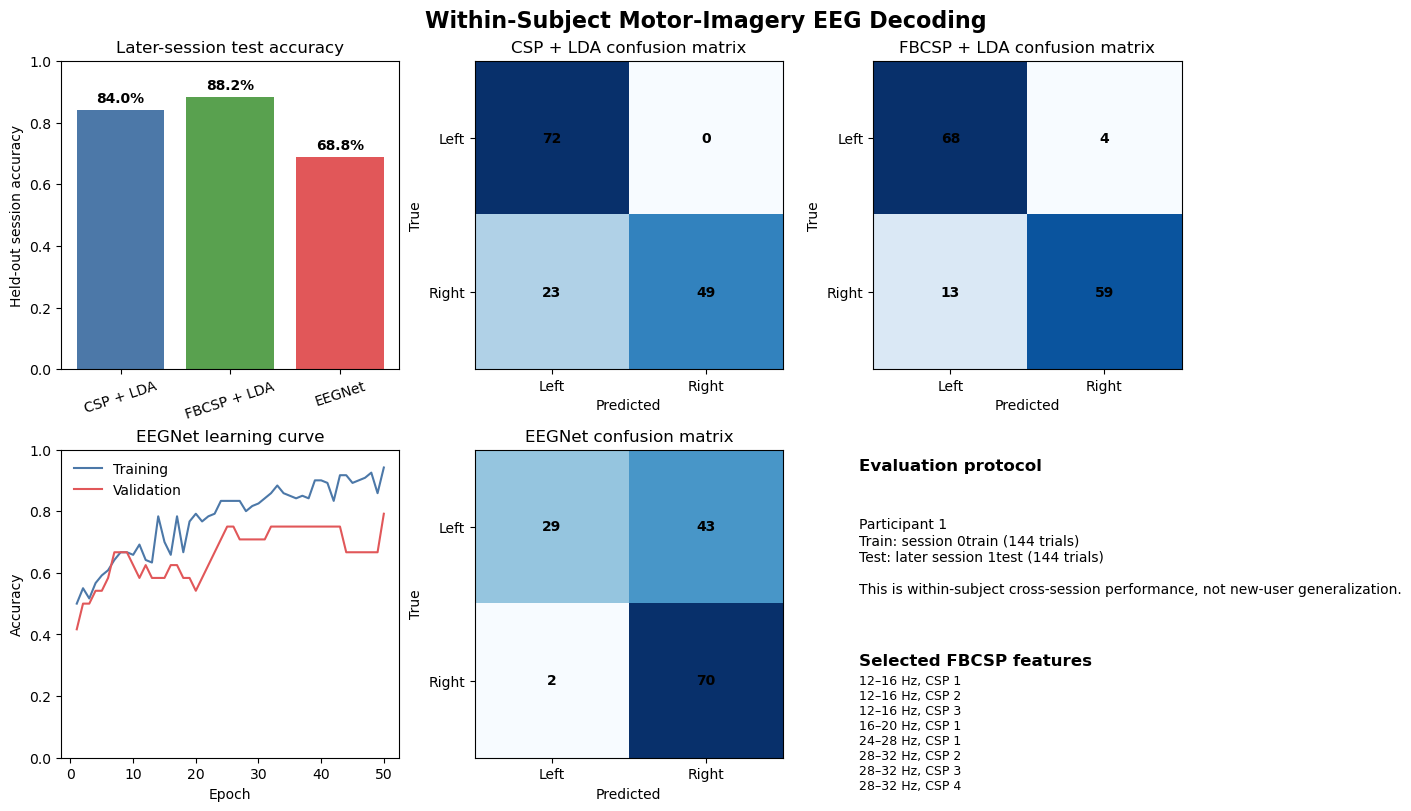

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

method_names = ["CSP + LDA", "FBCSP + LDA", "EEGNet"]
held_out_accuracies = [accuracy, fbcsp_accuracy, test_accuracy]
confusions = [
    cm,
    confusion_matrix(y_test_fb, fbcsp_predictions, labels=["left_hand", "right_hand"]),
    test_confusion,
]
class_labels = [["Left", "Right"], ["Left", "Right"], ["Left", "Right"]]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
fig.suptitle("Within-Subject Motor-Imagery EEG Decoding", fontsize=16, fontweight="bold")

bar_colors = ["#4C78A8", "#59A14F", "#E15759"]
axes[0, 0].bar(method_names, held_out_accuracies, color=bar_colors)
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel("Held-out session accuracy")
axes[0, 0].set_title("Later-session test accuracy")
axes[0, 0].tick_params(axis="x", rotation=18)
for i, value in enumerate(held_out_accuracies):
    axes[0, 0].text(i, value + 0.025, f"{value:.1%}", ha="center", fontweight="bold")

for ax, matrix, name, labels in zip(axes[0, 1:], confusions[:2], method_names[:2], class_labels[:2]):
    image = ax.imshow(matrix, cmap="Blues")
    ax.set_title(f"{name} confusion matrix")
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center", color="black", fontweight="bold")

axes[1, 0].plot(history["epoch"], history["train_accuracy"], label="Training", color="#4C78A8")
axes[1, 0].plot(history["epoch"], history["valid_accuracy"], label="Validation", color="#E15759")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_title("EEGNet learning curve")
axes[1, 0].legend(frameon=False)

axes[1, 1].imshow(confusions[2], cmap="Blues")
axes[1, 1].set_title("EEGNet confusion matrix")
axes[1, 1].set_xticks([0, 1], class_labels[2])
axes[1, 1].set_yticks([0, 1], class_labels[2])
axes[1, 1].set_xlabel("Predicted")
axes[1, 1].set_ylabel("True")
for row in range(2):
    for col in range(2):
        axes[1, 1].text(col, row, str(confusions[2][row, col]), ha="center", va="center", color="black", fontweight="bold")

selected_labels = []
for feature_index in selector.get_support(indices=True):
    band_index, component_index = divmod(feature_index, 4)
    low, high = frequency_bands[band_index]
    selected_labels.append(f"{low}–{high} Hz, CSP {component_index + 1}")
axes[1, 2].axis("off")
axes[1, 2].text(0, 0.97, "Evaluation protocol", fontsize=12, fontweight="bold", va="top")
axes[1, 2].text(0, 0.78, "Participant 1\nTrain: session 0train (144 trials)\nTest: later session 1test (144 trials)\n\nThis is within-subject cross-session performance, not new-user generalization.", va="top", fontsize=10)
axes[1, 2].text(0, 0.34, "Selected FBCSP features", fontsize=12, fontweight="bold", va="top")
axes[1, 2].text(0, 0.27, "\n".join(selected_labels), va="top", fontsize=9)

fig.savefig("motor_imagery_within_subject_results.png", dpi=220, bbox_inches="tight")
plt.show()


# Portfolio interpretation

## What I can honestly claim

I built a reproducible **within-subject, cross-session** EEG motor-imagery benchmark using the BCI Competition IV 2a dataset. I compared CSP + LDA, filter-bank CSP + LDA, and EEGNet for left- versus right-hand imagery, while keeping the later recording session untouched until final evaluation.

The comparison demonstrates how classical signal processing and compact deep learning behave on the same held-out EEG session. It also identifies which frequency-band/CSP features the FBCSP pipeline selected.

## What I cannot claim yet

These results are from **one participant**. They do not show that a model will work for a new user, which is a central challenge in practical BCIs. The next research step would be to repeat the protocol across participants and report the distribution of held-out session accuracy—not to add a flashier network.

## If an interviewer asks why this matters

“EEG is noisy and changes across recording sessions. I wanted to compare an interpretable signal-processing baseline against a compact neural network using a later session as the test set. That made the evaluation more realistic than randomly splitting trials, while keeping the scope small enough to inspect every step. I would next test cross-subject generalization and calibration data requirements.”

## Before sharing

1. Run the notebook from top to bottom in Colab or a local environment.
2. Confirm the figure is generated and use it in the repository README.
3. Keep the project framed as a **within-subject benchmark**; do not call it a deployable BCI or claim new-user generalization.
